In [3]:
import pandas as pd

In [4]:
df=pd.read_excel("../data/Afficionado Coffee Roasters.xlsx")

In [6]:
df.head()

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [7]:
df.shape

(149116, 11)

In [8]:
df.columns

Index(['transaction_id', 'year', 'transaction_time', 'transaction_qty',
       'store_id', 'store_location', 'product_id', 'unit_price',
       'product_category', 'product_type', 'product_detail'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   year              149116 non-null  int64  
 2   transaction_time  149116 non-null  object 
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  str    
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  str    
 9   product_type      149116 non-null  str    
 10  product_detail    149116 non-null  str    
dtypes: float64(1), int64(5), object(1), str(4)
memory usage: 19.8+ MB


In [10]:
df.isnull().sum()

transaction_id      0
year                0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe()

,transaction_id,year,transaction_qty,store_id,product_id,unit_price
count,149116.000000,149116.0,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,2025.0,1.438276,5.342063,47.918607,3.382219
std,43153.600016,0.0,0.542509,2.074241,17.930020,2.658723
min,1.000000,2025.0,1.000000,3.000000,1.000000,0.800000
25%,37335.750000,2025.0,1.000000,3.000000,33.000000,2.500000
50%,74727.500000,2025.0,1.000000,5.000000,47.000000,3.000000
75%,112094.250000,2025.0,2.000000,8.000000,60.000000,3.750000
max,149456.000000,2025.0,8.000000,8.000000,87.000000,45.000000


In [13]:
df["revenue"]=df["transaction_qty"]*df["unit_price"]

In [14]:
df.head()

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,revenue
0,1,2025,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg,6.0
1,2,2025,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2
2,3,2025,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,9.0
3,4,2025,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm,2.0
4,5,2025,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2


In [15]:
total_revenue=df["revenue"].sum()

In [16]:
print("Total Revenue:",total_revenue)

Total Revenue: 698812.3300000001


In [17]:
total_quantity=df["transaction_qty"].sum()

In [18]:
print("Total_quantity sold:",total_quantity)

Total_quantity sold: 214470


In [19]:
top_products=(
    df.groupby("product_detail")
["transaction_qty"]
    .sum()
    .sort_values(ascending=False)
)
top_products.head(10)

product_detail
Earl Grey Rg                   4708
Dark chocolate Lg              4668
Morning Sunrise Chai Rg        4643
Latte                          4602
Peppermint Rg                  4564
Columbian Medium Roast Rg      4547
Traditional Blend Chai Rg      4512
Latte Rg                       4497
Our Old Time Diner Blend Sm    4484
Serenity Green Tea Rg          4477
Name: transaction_qty, dtype: int64

In [20]:
least_products=(
    df.groupby("product_detail")
["transaction_qty"]
    .sum()
    .sort_values(ascending=True)
)
least_products.head(10)

product_detail
Dark chocolate                  118
Spicy Eye Opener Chai           122
Guatemalan Sustainably Grown    134
Earl Grey                       142
Jamacian Coffee River           146
Chili Mayan                     148
Columbian Medium Roast          148
Primo Espresso Roast            150
Lemon Grass                     152
Traditional Blend Chai          153
Name: transaction_qty, dtype: int64

In [21]:
product_revenue=(
    df.groupby("product_detail")
["revenue"]
    .sum()
    .sort_values(ascending=False)
)
product_revenue.head(10)

product_detail
Sustainably Grown Organic Lg    21151.75
Dark chocolate Lg               21006.00
Latte Rg                        19112.25
Cappuccino Lg                   17641.75
Morning Sunrise Chai Lg         17384.00
Latte                           17257.50
Jamaican Coffee River Lg        16481.25
Sustainably Grown Organic Rg    16233.75
Cappuccino                      15997.50
Brazilian Lg                    15109.50
Name: revenue, dtype: float64

In [22]:
category_revenue=(
    df.groupby("product_category")
["revenue"]
    .sum()
    .sort_values(ascending=False)
)
category_revenue

product_category
Coffee                269952.45
Tea                   196405.95
Bakery                 82315.64
Drinking Chocolate     72416.00
Coffee beans           40085.25
Branded                13607.00
Loose Tea              11213.60
Flavours                8408.80
Packaged Chocolate      4407.64
Name: revenue, dtype: float64

In [23]:
category_quantity=(
    df.groupby("product_category")
["transaction_qty"]
    .sum()
    .sort_values(ascending=False)
)
category_quantity

product_category
Coffee                89250
Tea                   69737
Bakery                23214
Drinking Chocolate    17457
Flavours              10511
Coffee beans           1828
Loose Tea              1210
Branded                 776
Packaged Chocolate      487
Name: transaction_qty, dtype: int64

In [24]:
average_price=(
    df.groupby("product_detail")
["unit_price"]
    .mean()
    .sort_values(ascending=False)
)
average_price.head(10)

product_detail
Civet Cat                   45.000000
I Need My Bean! T-shirt     27.886878
Organic Decaf Blend         22.609223
Ethiopia                    21.000000
Primo Espresso Roast        20.450000
Jamacian Coffee River       19.750000
Brazilian - Organic         18.000000
Our Old Time Diner Blend    18.000000
Columbian Medium Roast      15.000000
Espresso Roast              14.750000
Name: unit_price, dtype: float64

In [25]:
product_analysis = df.groupby("product_detail").agg(
    total_quantity=("transaction_qty", "sum"),
    total_revenue=("revenue", "sum"),
    average_price=("unit_price", "mean")
)

print(product_analysis)

                              total_quantity  total_revenue  average_price
product_detail                                                            
Almond Croissant                        1911        7168.13       3.750988
Brazilian - Organic                      214        3852.00      18.000000
Brazilian Lg                            4317       15109.50       3.500000
Brazilian Rg                            4385       13155.00       3.000000
Brazilian Sm                            4310        9482.00       2.200000
...                                      ...            ...            ...
Sustainably Grown Organic Lg            4453       21151.75       4.750000
Sustainably Grown Organic Rg            4329       16233.75       3.750000
Traditional Blend Chai                   153        1369.35       8.950000
Traditional Blend Chai Lg               4174       12522.00       3.000000
Traditional Blend Chai Rg               4512       11280.00       2.500000

[80 rows x 3 columns]


In [26]:
product_analysis.sort_values(
    "total_revenue",
    ascending=False
).head(10)

,total_quantity,total_revenue,average_price
product_detail,,,
Sustainably Grown Organic Lg,4453,21151.75,4.75
Dark chocolate Lg,4668,21006.00,4.50
Latte Rg,4497,19112.25,4.25
Cappuccino Lg,4151,17641.75,4.25
Morning Sunrise Chai Lg,4346,17384.00,4.00
Latte,4602,17257.50,3.75
Jamaican Coffee River Lg,4395,16481.25,3.75
Sustainably Grown Organic Rg,4329,16233.75,3.75
Cappuccino,4266,15997.50,3.75


In [27]:
product_analysis.sort_values(
    "total_quantity",
    ascending=False
).head(10)

,total_quantity,total_revenue,average_price
product_detail,,,
Earl Grey Rg,4708,11770.00,2.50
Dark chocolate Lg,4668,21006.00,4.50
Morning Sunrise Chai Rg,4643,11607.50,2.50
Latte,4602,17257.50,3.75
Peppermint Rg,4564,11410.00,2.50
Columbian Medium Roast Rg,4547,11367.50,2.50
Traditional Blend Chai Rg,4512,11280.00,2.50
Latte Rg,4497,19112.25,4.25
Our Old Time Diner Blend Sm,4484,8968.00,2.00


In [28]:
import matplotlib.pyplot as plt


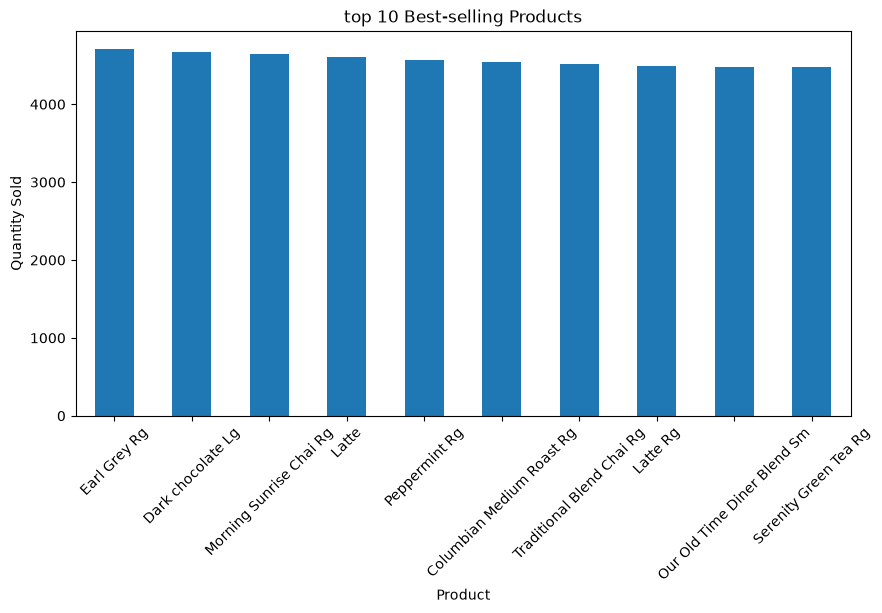

In [29]:
top_products.head(10).plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("top 10 Best-selling Products")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.show()

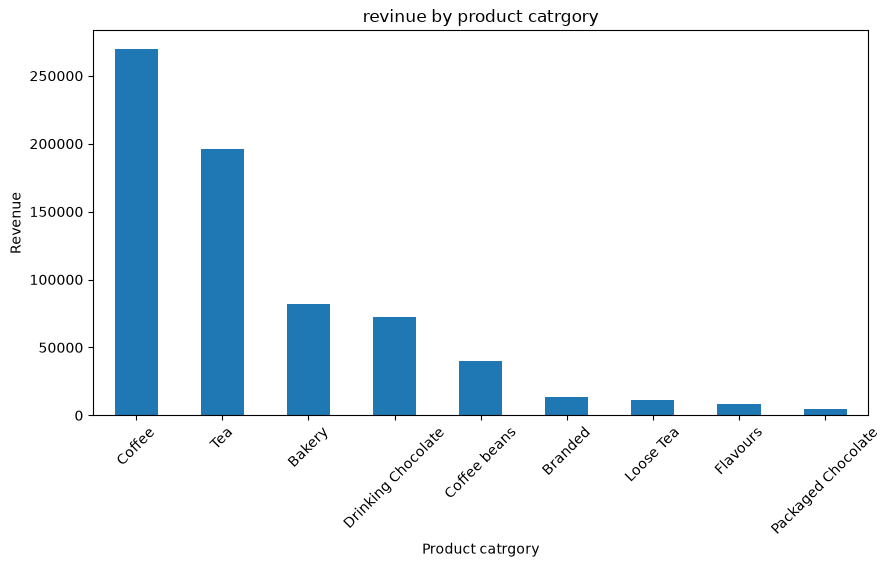

In [30]:
category_revenue.plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("revinue by product catrgory")
plt.xlabel("Product catrgory")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

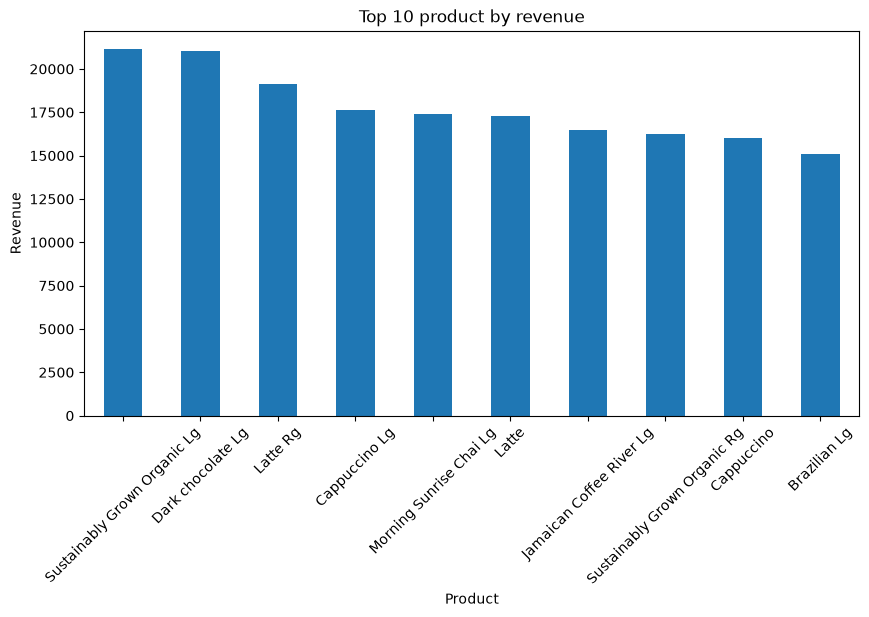

In [31]:
product_revenue.head(10).plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("Top 10 product by revenue")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

In [32]:
total_revenue=df["revenue"].sum()

In [33]:
total_revenue = df["revenue"].sum()
top_10_revenue =product_revenue.head(10).sum()
percentage=(top_10_revenue/total_revenue)*100
print("Top 10 products revenue percentage:",percentage)

Top 10 products revenue percentage: 25.382386999382224


In [34]:
product_analysis=product_analysis.sort_values(
    "total_revenue",
    ascending=False
)
product_analysis.head(10)

,total_quantity,total_revenue,average_price
product_detail,,,
Sustainably Grown Organic Lg,4453,21151.75,4.75
Dark chocolate Lg,4668,21006.00,4.50
Latte Rg,4497,19112.25,4.25
Cappuccino Lg,4151,17641.75,4.25
Morning Sunrise Chai Lg,4346,17384.00,4.00
Latte,4602,17257.50,3.75
Jamaican Coffee River Lg,4395,16481.25,3.75
Sustainably Grown Organic Rg,4329,16233.75,3.75
Cappuccino,4266,15997.50,3.75


In [35]:
product_analysis.to_excel(
    "../data/product_analysis.xlsx"
)

In [36]:
yearly_revenue = df.groupby("year")["revenue"].sum().reset_index()

print(yearly_revenue)
                                      

   year    revenue
0  2025  698812.33


In [37]:
df["transaction_time"] = pd.to_datetime(
    df["transaction_time"],
    format="%H:%M:%S"
)
df["hour"] = df["transaction_time"].dt.hour
hourly_revenue = df.groupby("hour")["revenue"].sum().reset_index()
print(hourly_revenue)

    hour   revenue
0      6  21900.27
1      7  63526.47
2      8  82699.87
3      9  85169.53
4     10  88673.39
5     11  46319.14
6     12  40192.79
7     13  40367.45
8     14  41304.74
9     15  41733.10
10    16  41122.75
11    17  40134.31
12    18  34286.20
13    19  28446.68
14    20   2935.64


In [38]:
print(df.head())

   transaction_id  year    transaction_time  transaction_qty  store_id  \
0               1  2025 1900-01-01 07:06:11                2         5   
1               2  2025 1900-01-01 07:08:56                2         5   
2               3  2025 1900-01-01 07:14:04                2         5   
3               4  2025 1900-01-01 07:20:24                1         5   
4               5  2025 1900-01-01 07:22:41                2         5   

    store_location  product_id  unit_price    product_category  \
0  Lower Manhattan          32         3.0              Coffee   
1  Lower Manhattan          57         3.1                 Tea   
2  Lower Manhattan          59         4.5  Drinking Chocolate   
3  Lower Manhattan          22         2.0              Coffee   
4  Lower Manhattan          57         3.1                 Tea   

            product_type               product_detail  revenue  hour  
0  Gourmet brewed coffee                  Ethiopia Rg      6.0     7  
1        Brewed 

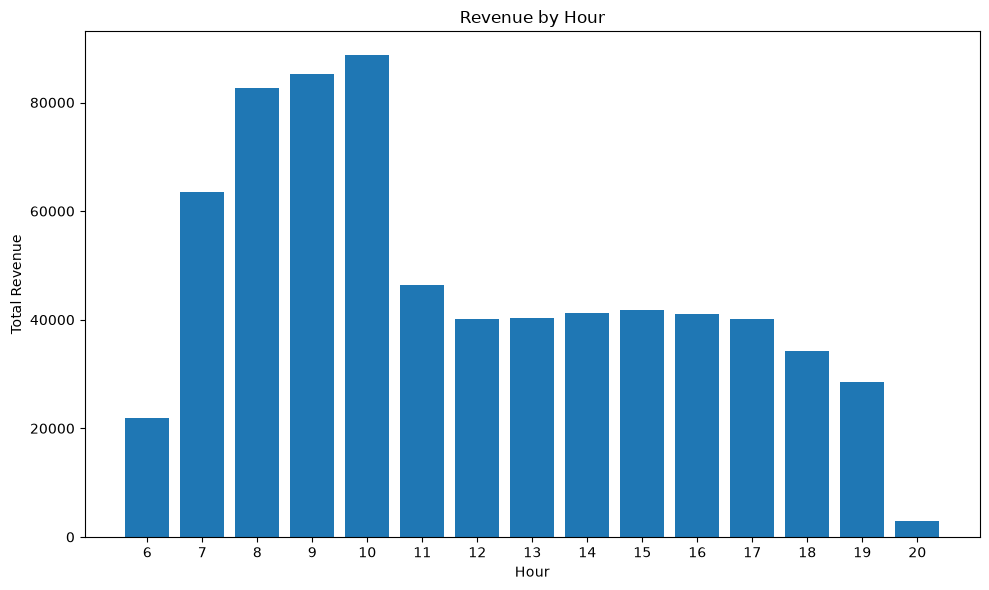

In [39]:
plt.figure(figsize=(10, 6))

plt.bar(
    hourly_revenue["hour"],
    hourly_revenue["revenue"]
)

plt.xlabel("Hour")
plt.ylabel("Total Revenue")
plt.title("Revenue by Hour")

plt.xticks(hourly_revenue["hour"])

plt.tight_layout()
plt.show()

In [40]:
least_selling = product_analysis.sort_values(
    "total_quantity",
    ascending=True
).head(10)

print(least_selling)

                              total_quantity  total_revenue  average_price
product_detail                                                            
Dark chocolate                           118         755.20           6.40
Spicy Eye Opener Chai                    122        1335.90          10.95
Guatemalan Sustainably Grown             134        1340.00          10.00
Earl Grey                                142        1270.90           8.95
Jamacian Coffee River                    146        2883.50          19.75
Columbian Medium Roast                   148        2220.00          15.00
Chili Mayan                              148        1972.84          13.33
Primo Espresso Roast                     150        3067.50          20.45
Lemon Grass                              152        1360.40           8.95
Peppermint                               153        1369.35           8.95


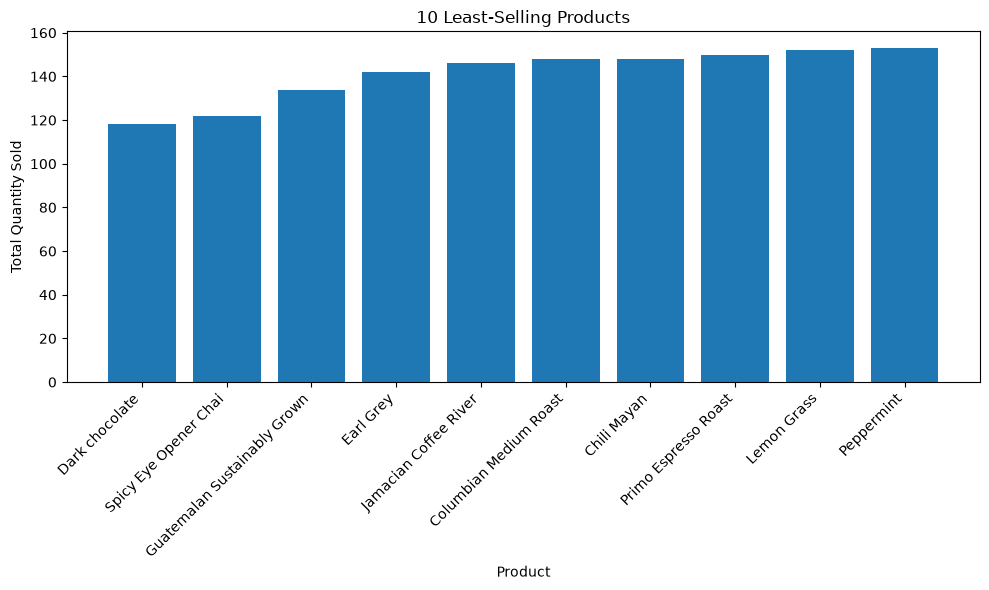

In [41]:
plt.figure(figsize=(10, 6))

plt.bar(
    least_selling.index,
    least_selling["total_quantity"]
)

plt.xlabel("Product")
plt.ylabel("Total Quantity Sold")
plt.title("10 Least-Selling Products")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

In [42]:
product_performance = product_analysis.copy()

product_performance["revenue_per_quantity"] = (
    product_performance["total_revenue"] /
    product_performance["total_quantity"]
)

print(product_performance.head(10))

                              total_quantity  total_revenue  average_price  \
product_detail                                                               
Sustainably Grown Organic Lg            4453       21151.75           4.75   
Dark chocolate Lg                       4668       21006.00           4.50   
Latte Rg                                4497       19112.25           4.25   
Cappuccino Lg                           4151       17641.75           4.25   
Morning Sunrise Chai Lg                 4346       17384.00           4.00   
Latte                                   4602       17257.50           3.75   
Jamaican Coffee River Lg                4395       16481.25           3.75   
Sustainably Grown Organic Rg            4329       16233.75           3.75   
Cappuccino                              4266       15997.50           3.75   
Brazilian Lg                            4317       15109.50           3.50   

                              revenue_per_quantity  
product_de

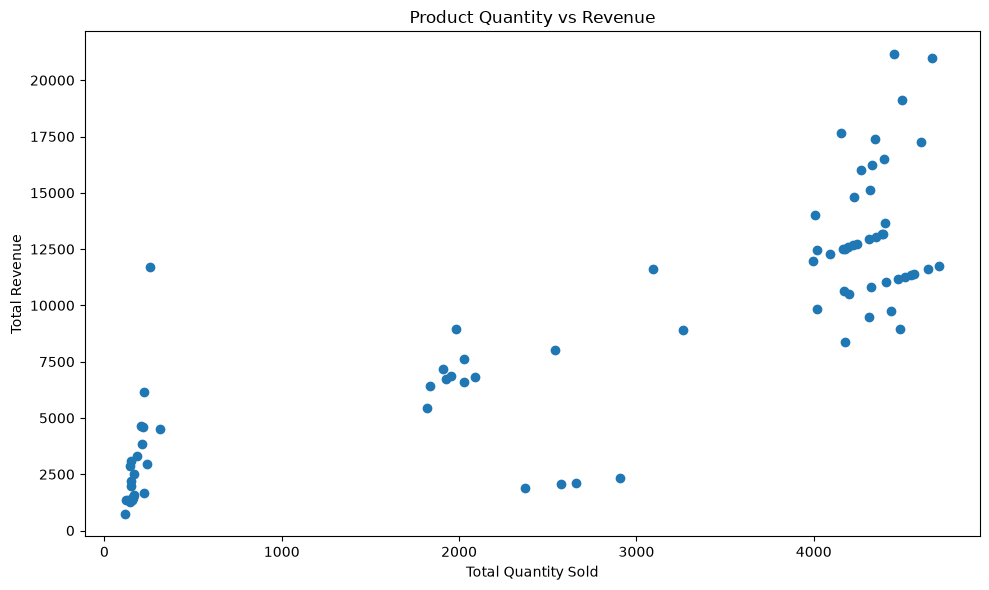

In [43]:
plt.figure(figsize=(10, 6))

plt.scatter(
    product_performance["total_quantity"],
    product_performance["total_revenue"]
)

plt.xlabel("Total Quantity Sold")
plt.ylabel("Total Revenue")
plt.title("Product Quantity vs Revenue")

plt.tight_layout()
plt.show()

In [44]:
best_products = product_analysis.sort_values(
    "total_revenue",
    ascending=False
).head(5)

print(best_products)

                              total_quantity  total_revenue  average_price
product_detail                                                            
Sustainably Grown Organic Lg            4453       21151.75           4.75
Dark chocolate Lg                       4668       21006.00           4.50
Latte Rg                                4497       19112.25           4.25
Cappuccino Lg                           4151       17641.75           4.25
Morning Sunrise Chai Lg                 4346       17384.00           4.00


In [46]:
category_analysis = df.groupby("product_category").agg(
    total_quantity=("transaction_qty", "sum"),
    total_revenue=("revenue", "sum"),
    average_price=("unit_price", "mean")
)

print(category_analysis)

                    total_quantity  total_revenue  average_price
product_category                                                
Bakery                       23214       82315.64       3.551682
Branded                        776       13607.00      17.720214
Coffee                       89250      269952.45       3.023646
Coffee beans                  1828       40085.25      21.018397
Drinking Chocolate           17457       72416.00       4.148827
Flavours                     10511        8408.80       0.800000
Loose Tea                     1210       11213.60       9.267438
Packaged Chocolate             487        4407.64       9.050595
Tea                          69737      196405.95       2.817121


In [47]:
best_category = category_analysis.sort_values(
    "total_revenue",
    ascending=False
)

print(best_category)

                    total_quantity  total_revenue  average_price
product_category                                                
Coffee                       89250      269952.45       3.023646
Tea                          69737      196405.95       2.817121
Bakery                       23214       82315.64       3.551682
Drinking Chocolate           17457       72416.00       4.148827
Coffee beans                  1828       40085.25      21.018397
Branded                        776       13607.00      17.720214
Loose Tea                     1210       11213.60       9.267438
Flavours                     10511        8408.80       0.800000
Packaged Chocolate             487        4407.64       9.050595


In [48]:
location_revenue = df.groupby("store_location")["revenue"].sum()

print(location_revenue.sort_values(ascending=False))

store_location
Hell's Kitchen     236511.17
Astoria            232243.91
Lower Manhattan    230057.25
Name: revenue, dtype: float64


In [49]:
best_store = location_revenue.idxmax()
highest_revenue = location_revenue.max()

print("Best Performing Store:", best_store)
print("Highest Revenue:", round(highest_revenue, 2))

Best Performing Store: Hell's Kitchen
Highest Revenue: 236511.17


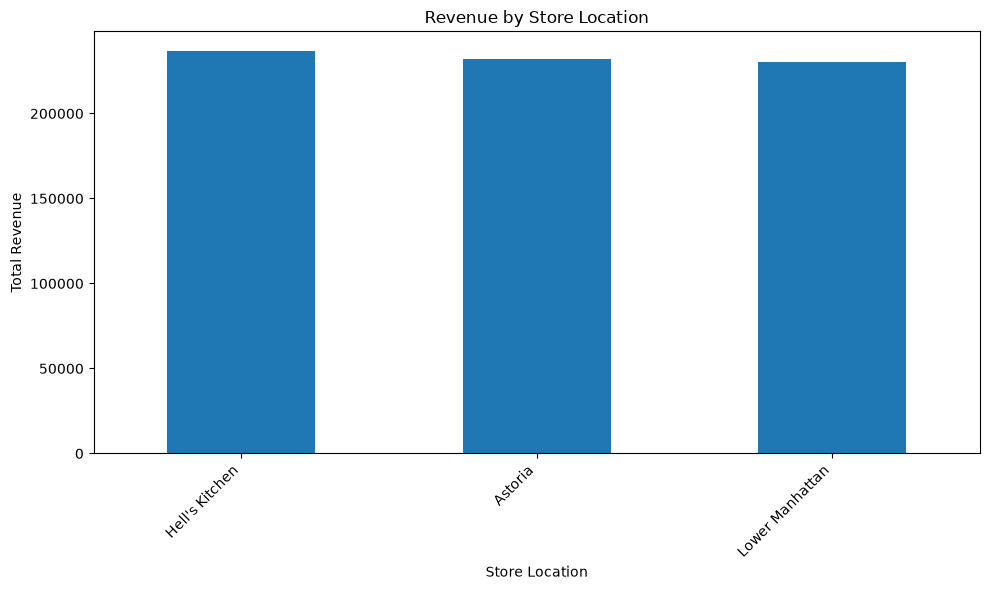

In [50]:
plt.figure(figsize=(10, 6))

location_revenue.sort_values(ascending=False).plot(kind="bar")

plt.xlabel("Store Location")
plt.ylabel("Total Revenue")
plt.title("Revenue by Store Location")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [51]:
print("===== COFFEE SALES ANALYTICS SUMMARY =====")

total_revenue = df["revenue"].sum()
total_quantity = df["transaction_qty"].sum()
total_transactions = df["transaction_id"].nunique()
total_products = df["product_detail"].nunique()
total_locations = df["store_location"].nunique()

print("Total Revenue:", round(total_revenue, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Transactions:", total_transactions)
print("Total Products:", total_products)
print("Total Store Locations:", total_locations)

===== COFFEE SALES ANALYTICS SUMMARY =====
Total Revenue: 698812.33
Total Quantity Sold: 214470
Total Transactions: 149116
Total Products: 80
Total Store Locations: 3


In [52]:
with pd.ExcelWriter("../data/Coffee_Sales_Analysis_Results.xlsx") as writer:
    product_analysis.to_excel(writer, sheet_name="Product Analysis")
    category_analysis.to_excel(writer, sheet_name="Category Analysis")
    location_revenue.to_frame("Total Revenue").to_excel(
        writer, sheet_name="Location Analysis"
    )

print("Analysis results saved successfully!")

Analysis results saved successfully!


In [53]:
# 1. Top 5 products by revenue
top_5_products = product_analysis.sort_values(
    "total_revenue", ascending=False
).head(5)

print("TOP 5 PRODUCTS BY REVENUE")
print(top_5_products)

# 2. Top 5 products by quantity
top_5_quantity = product_analysis.sort_values(
    "total_quantity", ascending=False
).head(5)

print("\nTOP 5 PRODUCTS BY QUANTITY")
print(top_5_quantity)

# 3. Best-performing category
best_category = category_analysis["total_revenue"].idxmax()

print("\nBEST-PERFORMING CATEGORY:", best_category)

# 4. Best-performing store location
best_store = location_revenue.idxmax()

print("BEST-PERFORMING STORE LOCATION:", best_store)

# 5. Highest revenue hour
best_hour = hourly_revenue.loc[
    hourly_revenue["revenue"].idxmax()
]

print("HIGHEST REVENUE HOUR:", int(best_hour["hour"]))
print("REVENUE AT THAT HOUR:", round(best_hour["revenue"], 2))

TOP 5 PRODUCTS BY REVENUE
                              total_quantity  total_revenue  average_price
product_detail                                                            
Sustainably Grown Organic Lg            4453       21151.75           4.75
Dark chocolate Lg                       4668       21006.00           4.50
Latte Rg                                4497       19112.25           4.25
Cappuccino Lg                           4151       17641.75           4.25
Morning Sunrise Chai Lg                 4346       17384.00           4.00

TOP 5 PRODUCTS BY QUANTITY
                         total_quantity  total_revenue  average_price
product_detail                                                       
Earl Grey Rg                       4708        11770.0           2.50
Dark chocolate Lg                  4668        21006.0           4.50
Morning Sunrise Chai Rg            4643        11607.5           2.50
Latte                              4602        17257.5           3.75
P